In [1]:

import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from torch import nn
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Create results folder
os.makedirs("Results/iTransformer", exist_ok=True)

# Load the same dataset used in previous models
data = joblib.load("Dataset/cycle_time_data.joblib")

print("Loaded object type:", type(data))

if hasattr(data, "shape"):
    print("Dataset shape:", data.shape)
elif isinstance(data, dict):
    print("Available keys:", list(data.keys()))

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())


Loaded object type: <class 'dict'>
Available keys: ['df', 'Xraw', 'yraw', 'features', 'train_end', 'stable', 'drift', 'recovery', 'window', 'drift_multiplier', 'recovery_multiplier']
PyTorch version: 2.15.0+cpu
CUDA available: False


In [2]:

# Extract dataset information
df = data["df"]
Xraw = data["Xraw"]
yraw = data["yraw"]

features = data["features"]
train_end = data["train_end"]
window = data["window"]

stable = data["stable"]
drift = data["drift"]
recovery = data["recovery"]

print("Dataset shape:", df.shape)
print("Xraw shape:", np.shape(Xraw))
print("yraw shape:", np.shape(yraw))

print("\nFeatures:", features)
print("Training ends at:", train_end)
print("Window size:", window)

print("\nEvaluation periods:")
print("Stable:", stable)
print("Drift:", drift)
print("Recovery:", recovery)

print("\nFirst five rows:")
display(df.head())


Dataset shape: (995, 18)
Xraw shape: (995, 5)
yraw shape: (995,)

Features: ['Processing_Time', 'Energy_Consumption', 'Machine_Availability', 'Upstream_Lag', 'Station_ID']
Training ends at: 400
Window size: 10

Evaluation periods:
Stable: (400, 600)
Drift: (600, 800)
Recovery: (800, None)

First five rows:


,Job_ID,Machine_ID,Operation_Type,Material_Used,Processing_Time,Energy_Consumption,Machine_Availability,Scheduled_Start,Scheduled_End,Actual_Start,Actual_End,Job_Status,Optimization_Category,Station_ID,Upstream_Lag,PT_orig,mult,phase
0,J002,M01,Grinding,3.35,79.0,6.61,84,3/18/2023 8:10,3/18/2023 9:29,3/18/2023 8:20,3/18/2023 9:39,Delayed,Low Efficiency,0,76.0,79.0,1.0,train
1,J004,M04,Grinding,1.76,106.0,12.50,95,3/18/2023 8:30,3/18/2023 10:16,3/18/2023 8:35,3/18/2023 10:21,Completed,Moderate Efficiency,1,56.0,106.0,1.0,train
2,J005,M01,Lathe,1.90,46.0,8.13,88,3/18/2023 8:40,3/18/2023 9:26,3/18/2023 8:42,3/18/2023 9:28,Completed,High Efficiency,0,79.0,46.0,1.0,train
3,J007,M04,Milling,4.67,22.0,14.20,87,3/18/2023 9:00,3/18/2023 9:22,3/18/2023 9:04,3/18/2023 9:26,Completed,Moderate Efficiency,1,106.0,22.0,1.0,train
4,J009,M02,Drilling,3.49,42.0,8.97,81,3/18/2023 9:20,3/18/2023 10:02,3/18/2023 9:23,3/18/2023 10:05,Completed,Moderate Efficiency,2,100.0,42.0,1.0,train


In [3]:

# Step 3: Data preprocessing for iTransformer

# Convert to NumPy arrays
X = np.asarray(Xraw, dtype=np.float32)
y = np.asarray(yraw, dtype=np.float32).reshape(-1, 1)

# Initialize scalers
scaler_X = StandardScaler()
scaler_y = StandardScaler()

# Fit only on initial training data
scaler_X.fit(X[:train_end])
scaler_y.fit(y[:train_end])

# Transform full dataset using training statistics
X_scaled = scaler_X.transform(X)
y_scaled = scaler_y.transform(y)

# Create sliding window sequences
def create_sequences(X_data, y_data, window_size):
    X_seq = []
    y_seq = []
    indices = []

    for i in range(window_size, len(X_data)):
        X_seq.append(X_data[i-window_size:i])
        y_seq.append(y_data[i, 0])
        indices.append(i)

    return (
        np.array(X_seq, dtype=np.float32),
        np.array(y_seq, dtype=np.float32),
        np.array(indices)
    )

X_seq, y_seq, indices = create_sequences(
    X_scaled, y_scaled, window
)

# Chronological training/test split
train_mask = indices < train_end
test_mask = indices >= train_end

X_train = X_seq[train_mask]
y_train = y_seq[train_mask]

X_test = X_seq[test_mask]
y_test = y_seq[test_mask]

test_indices = indices[test_mask]

print("Training X:", X_train.shape)
print("Training y:", y_train.shape)
print("Testing X:", X_test.shape)
print("Testing y:", y_test.shape)

print("\nTraining samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Test indices:", test_indices[0], "to", test_indices[-1])


Training X: (390, 10, 5)
Training y: (390,)
Testing X: (595, 10, 5)
Testing y: (595,)

Training samples: 390
Testing samples: 595
Test indices: 400 to 994


In [4]:

# Step 4: iTransformer architecture

import torch
import torch.nn as nn

# Reproducibility
torch.manual_seed(42)
np.random.seed(42)

class iTransformer(nn.Module):
    def __init__(
        self,
        seq_len=10,
        num_features=5,
        d_model=32,
        n_heads=4,
        n_layers=2,
        dropout=0.1
    ):
        super().__init__()

        # Embed each variable's temporal history
        self.embedding = nn.Linear(seq_len, d_model)

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=n_heads,
            dim_feedforward=64,
            dropout=dropout,
            batch_first=True,
            activation="gelu"
        )

        self.encoder = nn.TransformerEncoder(
            encoder_layer,
            num_layers=n_layers,
            enable_nested_tensor=False
        )

        # Forecasting head
        self.head = nn.Sequential(
            nn.Flatten(),
            nn.Linear(num_features * d_model, 64),
            nn.ReLU(),
            nn.Linear(64, 1)
        )

    def forward(self, x):
        # Input: (batch, time_steps, features)
        x = x.permute(0, 2, 1)

        # (batch, features, d_model)
        x = self.embedding(x)

        # Attention across features
        x = self.encoder(x)

        # Predict next target value
        return self.head(x).squeeze(-1)


device = torch.device("cpu")

model = iTransformer(
    seq_len=window,
    num_features=X_train.shape[2]
).to(device)

print(model)

# Test forward pass
sample = torch.tensor(
    X_train[:4],
    dtype=torch.float32
).to(device)

with torch.no_grad():
    output = model(sample)

print("\nInput shape:", sample.shape)
print("Output shape:", output.shape)

print(
    "Total parameters:",
    sum(p.numel() for p in model.parameters())
)


iTransformer(
  (embedding): Linear(in_features=10, out_features=32, bias=True)
  (encoder): TransformerEncoder(
    (layers): ModuleList(
      (0-1): 2 x TransformerEncoderLayer(
        (self_attn): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=32, out_features=32, bias=True)
        )
        (linear1): Linear(in_features=32, out_features=64, bias=True)
        (dropout): Dropout(p=0.1, inplace=False)
        (linear2): Linear(in_features=64, out_features=32, bias=True)
        (norm1): LayerNorm((32,), eps=1e-05, elementwise_affine=True, bias=True)
        (norm2): LayerNorm((32,), eps=1e-05, elementwise_affine=True, bias=True)
        (dropout1): Dropout(p=0.1, inplace=False)
        (dropout2): Dropout(p=0.1, inplace=False)
      )
    )
  )
  (head): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=160, out_features=64, bias=True)
    (2): ReLU()
    (3): Linear(in_features=64, out_features=1, bias=True)
 

In [5]:

# Step 5: Train iTransformer

from torch.utils.data import TensorDataset, DataLoader
import time

torch.manual_seed(42)
torch.set_num_threads(2)

# Convert training data to tensors
X_train_tensor = torch.tensor(
    X_train, dtype=torch.float32
)

y_train_tensor = torch.tensor(
    y_train, dtype=torch.float32
)

# Create DataLoader
train_dataset = TensorDataset(
    X_train_tensor,
    y_train_tensor
)

train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True
)

# Loss function and optimizer
criterion = nn.MSELoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

epochs = 100
train_losses = []

start_time = time.time()

for epoch in range(epochs):

    model.train()
    running_loss = 0.0

    for X_batch, y_batch in train_loader:

        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        optimizer.zero_grad()

        predictions = model(X_batch)

        loss = criterion(
            predictions,
            y_batch
        )

        loss.backward()
        optimizer.step()

        running_loss += (
            loss.item() * X_batch.size(0)
        )

    epoch_loss = running_loss / len(train_dataset)
    train_losses.append(epoch_loss)

    if (epoch + 1) % 10 == 0:
        print(
            f"Epoch {epoch+1}/{epochs}, "
            f"Training Loss: {epoch_loss:.6f}"
        )

training_time = time.time() - start_time

print("\nTraining completed!")
print(f"Training time: {training_time:.2f} seconds")

# Save trained model
torch.save(
    model.state_dict(),
    "Results/iTransformer/itransformer_model.pth"
)

print("Model saved successfully.")


Epoch 10/100, Training Loss: 0.378599
Epoch 20/100, Training Loss: 0.083045
Epoch 30/100, Training Loss: 0.041594
Epoch 40/100, Training Loss: 0.028247
Epoch 50/100, Training Loss: 0.020466
Epoch 60/100, Training Loss: 0.020368
Epoch 70/100, Training Loss: 0.022709
Epoch 80/100, Training Loss: 0.020223
Epoch 90/100, Training Loss: 0.016736
Epoch 100/100, Training Loss: 0.015299

Training completed!
Training time: 14.59 seconds
Model saved successfully.


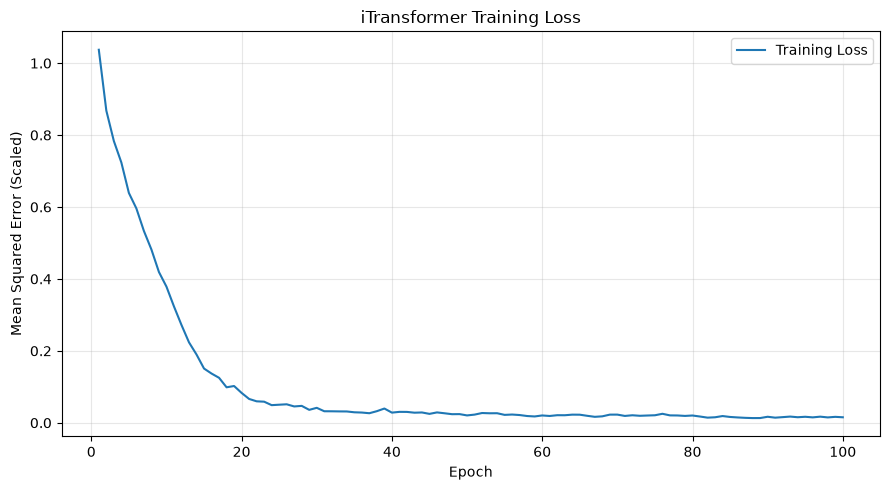

In [6]:

plt.figure(figsize=(9, 5))

plt.plot(
    range(1, epochs + 1),
    train_losses,
    label="Training Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error (Scaled)")
plt.title("iTransformer Training Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "Results/iTransformer/training_loss.png",
    dpi=300
)

plt.show()


In [7]:

# Step 6: iTransformer predictions and evaluation

from sklearn.metrics import mean_absolute_error, mean_squared_error

# Generate predictions
model.eval()

X_test_tensor = torch.tensor(
    X_test, dtype=torch.float32
).to(device)

with torch.no_grad():
    predictions_scaled = model(
        X_test_tensor
    ).cpu().numpy().reshape(-1, 1)

# Convert predictions back to original units
y_pred = scaler_y.inverse_transform(
    predictions_scaled
).flatten()

y_actual = scaler_y.inverse_transform(
    y_test.reshape(-1, 1)
).flatten()

# Evaluate each period
def evaluate_period(name, start, end):
    mask = test_indices >= start

    if end is not None:
        mask &= test_indices < end

    actual = y_actual[mask]
    predicted = y_pred[mask]

    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(
        mean_squared_error(actual, predicted)
    )

    return {
        "Period": name,
        "Samples": len(actual),
        "MAE": round(mae, 4),
        "RMSE": round(rmse, 4)
    }

results = [
    evaluate_period("Stable", *stable),
    evaluate_period("Drift", *drift),
    evaluate_period("Recovery", *recovery),
    evaluate_period("Overall", train_end, None)
]

results_df = pd.DataFrame(results)

print("iTransformer Evaluation Results")
display(results_df)

# Save results
results_df.to_csv(
    "Results/iTransformer/metrics.csv",
    index=False
)

# Save actual and predicted values
predictions_df = pd.DataFrame({
    "Index": test_indices,
    "Actual": y_actual,
    "Predicted": y_pred
})

predictions_df.to_csv(
    "Results/iTransformer/predictions.csv",
    index=False
)

print("Metrics and predictions saved successfully.")


iTransformer Evaluation Results


,Period,Samples,MAE,RMSE
0,Stable,200,26.7431,32.5068
1,Drift,200,59.9613,72.1213
2,Recovery,195,33.6044,39.2426
3,Overall,595,40.1575,51.0714


Metrics and predictions saved successfully.


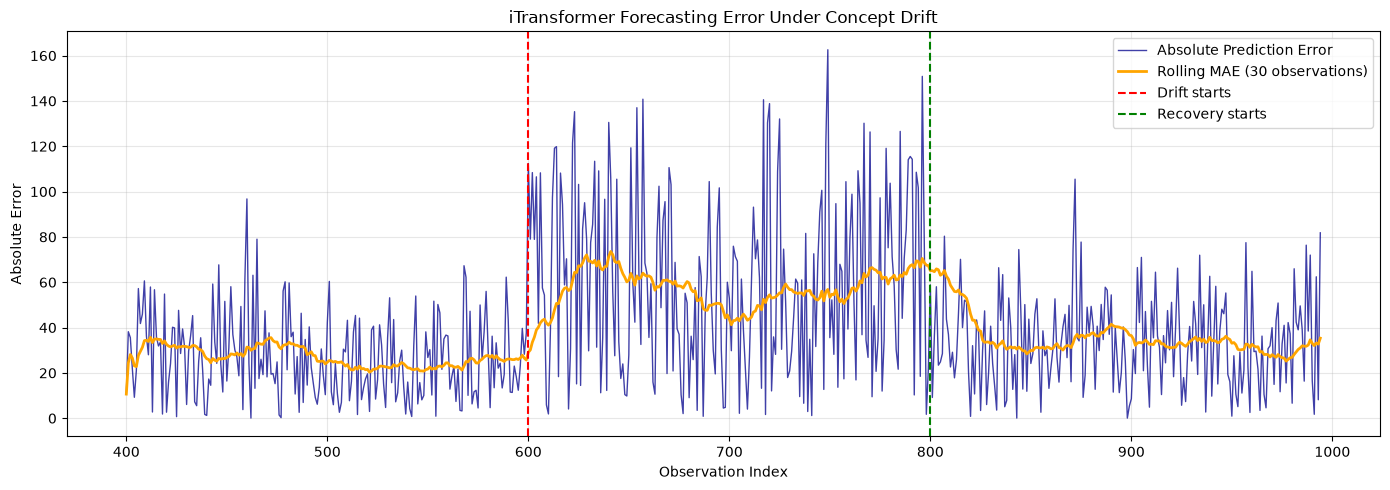

In [8]:

# Step 7: iTransformer error analysis

absolute_errors = np.abs(y_actual - y_pred)

fig, ax = plt.subplots(figsize=(14, 5))

ax.plot(
    test_indices,
    absolute_errors,
    color="darkblue",
    linewidth=1,
    alpha=0.75,
    label="Absolute Prediction Error"
)

# Rolling mean of absolute error
rolling_error = pd.Series(
    absolute_errors
).rolling(window=30, min_periods=1).mean()

ax.plot(
    test_indices,
    rolling_error,
    color="orange",
    linewidth=2,
    label="Rolling MAE (30 observations)"
)

ax.axvline(
    600, color="red", linestyle="--",
    label="Drift starts"
)

ax.axvline(
    800, color="green", linestyle="--",
    label="Recovery starts"
)

ax.set_xlabel("Observation Index")
ax.set_ylabel("Absolute Error")
ax.set_title("iTransformer Forecasting Error Under Concept Drift")

ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(
    "Results/iTransformer/error_analysis.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()
